# 01f — GARCHGRU · Vol / Risk Regression · stocks

**Job:** `J01_vol_risk` | **Phase:** P1 | **Status:** active

**Architecture:** GARCH(1,1)-GRU hybrid cell (embedded conditional-variance recursion)

**QLIKE run checklist:** set `LOSS = "qlike"` in section 0 (saves to `garchgru_qlike_*` artifacts, does not overwrite Huber). Run sections 1→6 in order. Huber full run is already saved — skip re-training unless `LOSS = "huber"`.

**Project path (WSL):** `~/ai-workspace/experiments/stock-prediction`

**Kernel:** select **`Python (stock-prediction)`** in the kernel picker (register with `bash scripts/install-jupyter-kernel.sh` if missing).

```bash
cd ~/ai-workspace/experiments/stock-prediction
source .venv/bin/activate
```


## 0) Run configuration

`fast_dev` = 200 symbols / 30 epochs (quick tests). `full` = entire universe / 100 epochs.

Set `LOSS` here — `"qlike"` for the crisis under-prediction experiment (separate artifact stem).

In [ ]:
# --- ML Iteration 2 job config (do not rename without updating scaffold) ---
JOB_ID = "01"
JOB_SLUG = "vol_risk"
ARCHITECTURE = "garchgru"
UNIVERSE = "stocks"
ASSET_TYPE = "stock"
TARGET_TYPE = "abs_return"
UNIVERSE_PREFIX = "stocks_universe"
TARGET_SUFFIX = ""

RUN_MODE = "full"  # "fast_dev" | "full"
FAST_DEV_MAX_SYMBOLS = 200
# Full bundle is rebuilt and verified separately before training.
FORCE_REBUILD_DATA = False
FAST_DEV_EPOCHS = 30
FULL_EPOCHS = 100

LOSS = "qlike"  # "huber" | "qlike" | "mse" — qlike penalizes vol underprediction harder

processed_dir = None

if RUN_MODE == "fast_dev":
    DATASET_TAG = f"dev{FAST_DEV_MAX_SYMBOLS}"
    sequences_name = f"{UNIVERSE_PREFIX}_{DATASET_TAG}{TARGET_SUFFIX}_sequences_plus5.npz"
    config_name = f"pipeline_config_{UNIVERSE_PREFIX}_{DATASET_TAG}{TARGET_SUFFIX}_plus5.json"
    scaler_name = f"scaler_{UNIVERSE_PREFIX}_{DATASET_TAG}{TARGET_SUFFIX}_plus5.json"
    MODEL_TAG = f"_{DATASET_TAG}"
    TRAIN_EPOCHS = FAST_DEV_EPOCHS
else:
    DATASET_TAG = "full"
    sequences_name = f"{UNIVERSE_PREFIX}{TARGET_SUFFIX}_sequences_plus5.npz"
    config_name = f"pipeline_config_{UNIVERSE_PREFIX}{TARGET_SUFFIX}_plus5.json"
    scaler_name = f"scaler_{UNIVERSE_PREFIX}{TARGET_SUFFIX}_plus5.json"
    MODEL_TAG = ""
    TRAIN_EPOCHS = FULL_EPOCHS

MODEL_ARCHITECTURE = f"{ARCHITECTURE}_qlike" if LOSS == "qlike" else ARCHITECTURE
ARTIFACT_STEM = f"{MODEL_ARCHITECTURE}_{JOB_SLUG}_{UNIVERSE}{MODEL_TAG}_tf"

print(
    f"JOB=J{JOB_ID}_{JOB_SLUG} | ARCH={ARCHITECTURE} | LOSS={LOSS} | UNIVERSE={UNIVERSE} | "
    f"RUN_MODE={RUN_MODE} | epochs={TRAIN_EPOCHS} | sequences={sequences_name}"
)
print(f"Artifact stem: {ARTIFACT_STEM}")


## 1) Setup

Import dependencies, configure paths, seed randomness, and print TensorFlow device info.

In [2]:
import sys
from pathlib import Path
for _c in [Path.cwd(), *Path.cwd().parents]:
    _s = _c / "scripts"
    if (_s / "notebook_bootstrap.py").exists():
        sys.path.insert(0, str(_s))
        break
from notebook_bootstrap import ensure_scripts_path
ensure_scripts_path()

from __future__ import annotations

import json
import random
import shutil
import subprocess
import sys
import tempfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name in ("04_ML_Model_Iteration-2", "ML_Iteration_2", "best model", "scripts"):
    ROOT = ROOT.parent
if not (ROOT / "scripts" / "tf_data.py").exists():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "scripts" / "tf_data.py").exists():
            ROOT = candidate.resolve()
            break
if str(ROOT / "scripts") not in sys.path:
    sys.path.insert(0, str(ROOT / "scripts"))

from tf_data import load_sequence_bundle
from tf_notebook_utils import bootstrap_notebook, configure_tf_gpu

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT, MODELS_DIR, DATASET_DIR, tf = bootstrap_notebook(SEED)
processed_dir = PROJECT_ROOT / "data" / "processed"
device_info = configure_tf_gpu(tf, enable_mixed_precision=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"TensorFlow:   {tf.__version__}")
print(f"GPU devices:  {device_info['gpus'] or 'None'}")
print(f"Mixed prec.:  {device_info['mixed_precision']}")
if device_info["platform_note"]:
    print(f"NOTE: {device_info['platform_note']}")
print(f"Seed: {SEED}")

I0000 00:00:1783770021.024891   12551 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1783770021.058289   12551 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1783770021.759085   12551 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Project root: /home/friyekekanu/ai-workspace/experiments/stock-prediction
TensorFlow:   2.21.0
GPU devices:  ['/physical_device:GPU:0']
Mixed prec.:  mixed_float16
Seed: 42


W0000 00:00:1783770022.715160   12551 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


## 2) Preprocess stocks (stock, plus5 profile)

Reuse existing artifacts when available. **Fast-dev** builds `dev{N}` files via `--max-symbols`.

In [ ]:
FULL_UNIVERSE_ARTIFACTS = {
    "sequences": processed_dir / f"{UNIVERSE_PREFIX}{TARGET_SUFFIX}_sequences_plus5.npz",
    "config": processed_dir / f"pipeline_config_{UNIVERSE_PREFIX}{TARGET_SUFFIX}_plus5.json",
    "scaler": processed_dir / f"scaler_{UNIVERSE_PREFIX}{TARGET_SUFFIX}_plus5.json",
}

seq_path = processed_dir / sequences_name
seq_bundle_dir = seq_path.with_suffix("")
cfg_path = processed_dir / config_name
scaler_path = processed_dir / scaler_name

# Full-universe runs are disk-backed directories; dev runs remain NPZ.
sequences_ready = seq_bundle_dir.exists() or seq_path.exists()
artifacts_ready = sequences_ready and cfg_path.exists() and scaler_path.exists()


def _backup_full_universe_artifacts() -> Path | None:
    existing = [p for p in FULL_UNIVERSE_ARTIFACTS.values() if p.exists()]
    if not existing:
        return None
    backup_dir = Path(tempfile.mkdtemp(prefix="universe_full_backup_"))
    for path in existing:
        shutil.copy2(path, backup_dir / path.name)
    print(f"Backed up {len(existing)} full-universe artifact(s) to {backup_dir}")
    return backup_dir


def _restore_full_universe_artifacts(backup_dir: Path | None) -> None:
    if backup_dir is None:
        return
    for path in backup_dir.iterdir():
        shutil.copy2(path, processed_dir / path.name)
    print("Restored full-universe artifacts after fast-dev preprocessing.")


def _promote_standard_to_dev_artifacts() -> None:
    promotions = [
        (FULL_UNIVERSE_ARTIFACTS["sequences"], seq_path),
        (FULL_UNIVERSE_ARTIFACTS["config"], cfg_path),
        (FULL_UNIVERSE_ARTIFACTS["scaler"], scaler_path),
    ]
    for src, dst in promotions:
        if not src.exists():
            raise FileNotFoundError(f"Expected preprocessing output missing: {src}")
        if dst.exists():
            dst.unlink()
        shutil.move(src, dst)
        print(f"Promoted -> {dst.name}")


prep_cmd = [
    sys.executable,
    str(PROJECT_ROOT / "scripts" / "run_preprocessing.py"),
    "--profile",
    "plus5",
    "--symbol-scope",
    "all",
    "--asset-type",
    ASSET_TYPE,
    "--target-type",
    TARGET_TYPE,
    "--history-outlier-filter",
    "none",
]

if RUN_MODE == "fast_dev":
    prep_cmd.extend(["--max-symbols", str(FAST_DEV_MAX_SYMBOLS)])

if artifacts_ready and not FORCE_REBUILD_DATA:
    print(f"Using existing {RUN_MODE} artifacts for stocks universe (stock) (skip rebuild).")
    print(f"- {seq_bundle_dir if seq_bundle_dir.exists() else seq_path}")
elif RUN_MODE == "fast_dev":
    print(
        f"Running fast-dev preprocessing ({FAST_DEV_MAX_SYMBOLS} symbols, {ASSET_TYPE}) "
        f"-> {DATASET_TAG} artifacts..."
    )
    backup_dir = _backup_full_universe_artifacts()
    try:
        subprocess.run(prep_cmd, cwd=PROJECT_ROOT, check=True)
        _promote_standard_to_dev_artifacts()
    finally:
        _restore_full_universe_artifacts(backup_dir)
    print("Fast-dev preprocessing complete.")
else:
    print(f"Running preprocessing for full {UNIVERSE} universe (plus5, {ASSET_TYPE})...")
    subprocess.run(prep_cmd, cwd=PROJECT_ROOT, check=True)
    print("Preprocessing complete.")


## 3) Load universe sequence artifacts

Load pooled universe arrays and validate the expected 15-feature input schema.

In [ ]:
bundle = load_sequence_bundle(
    sequences_name=sequences_name,
    config_name=config_name,
    scaler_name=scaler_name,
)

expected_features = [
    "log_return",
    "abs_return",
    "squared_return",
    "intraday_range",
    "range_ratio",
    "volatility_5",
    "volatility_21",
    "log_volume",
    "volume_surge",
    "spy_volatility_21",
    "return_ma_21",
    "rsi_14",
    "volatility_ratio_5_21",
    "lag_abs_return_1",
    "spy_log_return",
]

if bundle.feature_cols != expected_features:
    raise ValueError(
        "Feature mismatch. Expected plus5 15-feature universe set.\n"
        f"Expected: {expected_features}\nGot: {bundle.feature_cols}"
    )

# Keep disk-backed arrays lazy. Calling .astype() here would copy the entire
# full-universe tensor into RAM and can terminate WSL via the OOM killer.
X_train, y_train = bundle.X_train, bundle.y_train
X_val, y_val = bundle.X_val, bundle.y_val
X_test, y_test = bundle.X_test, bundle.y_test

print(f"Run mode: {RUN_MODE} ({DATASET_TAG})")
print(f"Storage: {bundle.storage_format}")
print(f"Symbols in config: {bundle.cfg.get('n_symbols', 'n/a')}")
print(f"Train/val/test: {X_train.shape[0]}/{X_val.shape[0]}/{X_test.shape[0]}")
print(f"Lookback: {bundle.cfg['lookback_days']}")
print(f"Features ({len(bundle.feature_cols)}): {bundle.feature_cols}")

## 4) Build and train GARCHGRU

GARCH(1,1)-GRU hybrid cell. Loss set in section 0 (`LOSS`). Early stopping on validation MAE.

> **Huber full run already saved.** With `LOSS="qlike"`, artifacts go to `garchgru_qlike_vol_risk_stocks_tf_*`.

In [ ]:
import sys
from pathlib import Path
for _c in [Path.cwd(), *Path.cwd().parents]:
    _s = _c / "scripts"
    if (_s / "notebook_bootstrap.py").exists():
        sys.path.insert(0, str(_s))
        break
from notebook_bootstrap import ensure_scripts_path
ensure_scripts_path()

from tf_notebook_utils import (
    build_regressor,
    make_tf_datasets,
    predict_in_batches,
    persistence_mae,
    as_1d_predictions,
    asymmetric_error_metrics,
)

BATCH_SIZE = 512 if device_info["using_gpu"] else 1024
EPOCHS = TRAIN_EPOCHS
PATIENCE = 8  # GARCH-GRU plateaus early; avoid long non-improving full-run epochs.
LR = 1e-3

n_features = X_train.shape[-1]
lookback = X_train.shape[1]

ARCH_KWARGS = {}
if ARCHITECTURE == "garchgru":
    ARCH_KWARGS["return_idx"] = bundle.feature_cols.index("log_return")

train_ds, val_ds = make_tf_datasets(X_train, y_train, X_val, y_val, batch_size=BATCH_SIZE)
model = build_regressor(ARCHITECTURE, lookback, n_features, lr=LR, loss=LOSS, **ARCH_KWARGS)
model.summary()

steps_per_epoch = int(np.ceil(len(X_train) / BATCH_SIZE))
print(f"Run mode: {RUN_MODE} | Architecture: {ARCHITECTURE} | Loss: {LOSS} | Epoch cap: {EPOCHS}")
print(f"Artifact stem: {ARTIFACT_STEM}")
print(f"Steps/epoch: {steps_per_epoch:,} | Batch size: {BATCH_SIZE}")
if device_info.get("using_gpu"):
    print(
        "GPU note: first epoch can take 10–30+ min on RTX 5090 while TF JIT-compiles CUDA kernels. "
        "This is normal — wait for epoch 1 output; later epochs are faster."
    )

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_mae",
        mode="min",
        patience=PATIENCE,
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODELS_DIR / f"{ARTIFACT_STEM}_epoch{{epoch:03d}}.keras"),
        monitor="val_mae",
        mode="min",
        save_best_only=True,
        save_weights_only=False,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=7,
        min_lr=1e-5,
        verbose=1,
    ),
]

with tf.device("/GPU:0" if device_info["using_gpu"] else "/CPU:0"):
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1,
    )

# Contiguous batch prediction avoids Keras materializing a complete memmap.
val_pred = as_1d_predictions(predict_in_batches(model, X_val, BATCH_SIZE))
test_pred = as_1d_predictions(predict_in_batches(model, X_test, BATCH_SIZE))

val_mae = float(np.mean(np.abs(val_pred - y_val)))
val_rmse = float(np.sqrt(np.mean((val_pred - y_val) ** 2)))
test_mae = float(np.mean(np.abs(test_pred - y_test)))
test_rmse = float(np.sqrt(np.mean((test_pred - y_test) ** 2)))

best_epoch = int(np.argmin(history.history["val_mae"]) + 1)
best_val_mae = float(np.min(history.history["val_mae"]))

persistence_mae_val = persistence_mae(X_val, y_val, bundle.feature_cols, bundle.scaler)
persistence_mae_test = persistence_mae(X_test, y_test, bundle.feature_cols, bundle.scaler)
train_mean = float(np.mean(y_train))
train_mean_mae_val = float(np.mean(np.abs(train_mean - y_val)))
train_mean_mae_test = float(np.mean(np.abs(train_mean - y_test)))

asym_val = asymmetric_error_metrics(y_val, val_pred)
asym_crisis = asymmetric_error_metrics(y_test, test_pred)

print(f"Best epoch: {best_epoch} | Best val MAE: {best_val_mae:.6f}")
print(f"Val  MAE: {val_mae:.6f} | RMSE: {val_rmse:.6f}")
print(f"Crisis MAE (Test 2020 Q1): {test_mae:.6f} | RMSE: {test_rmse:.6f}")
print(
    f"Crisis asymmetry: under-MAE {asym_crisis['under_mae']:.6f} vs over-MAE "
    f"{asym_crisis['over_mae']:.6f} (under-prediction rate {asym_crisis['under_rate']:.1%})"
)
print("Baselines:")
print(f"  Persistence MAE (val):  {persistence_mae_val:.6f}")
print(f"  Persistence MAE (test): {persistence_mae_test:.6f}")
print(f"  Train-mean MAE (test):  {train_mean_mae_test:.6f}")

baseline_pred_path = MODELS_DIR / f"baseline_{JOB_SLUG}_{UNIVERSE}{MODEL_TAG}_tf_predictions.json"
baseline_comparison = {"baseline_trained": False}
if baseline_pred_path.exists():
    with open(baseline_pred_path) as f:
        baseline_payload = json.load(f)
    beats_val = val_mae < baseline_payload.get("val_mae", float("inf"))
    beats_crisis = test_mae < baseline_payload.get("crisis_mae", float("inf"))
    baseline_comparison = {
        "baseline_trained": True,
        "baseline_artifact": baseline_pred_path.name,
        "baseline_val_mae": baseline_payload.get("val_mae"),
        "baseline_crisis_mae": baseline_payload.get("crisis_mae"),
        "beats_baseline_val_mae": beats_val,
        "beats_baseline_crisis_mae": beats_crisis,
        "delta_val_mae": float(val_mae - baseline_payload.get("val_mae", val_mae)),
        "delta_crisis_mae": float(test_mae - baseline_payload.get("crisis_mae", test_mae)),
        "promotion_eligible": beats_val and beats_crisis,
    }
    sign_v = "beats" if baseline_comparison["beats_baseline_val_mae"] else "loses to"
    sign_c = "beats" if baseline_comparison["beats_baseline_crisis_mae"] else "loses to"
    print(f"Vs trained baseline: model {sign_v} baseline on val MAE ({val_mae:.6f} vs {baseline_payload['val_mae']:.6f})")
    print(f"Vs trained baseline: model {sign_c} baseline on crisis MAE ({test_mae:.6f} vs {baseline_payload['crisis_mae']:.6f})")
    print(f"Promotion eligible (both MAE): {baseline_comparison['promotion_eligible']}")
else:
    print("Vs trained baseline: run 00a_baseline_* notebook first to enable comparison.")

huber_pred_path = MODELS_DIR / f"{ARCHITECTURE}_{JOB_SLUG}_{UNIVERSE}{MODEL_TAG}_tf_predictions.json"
huber_comparison = {"huber_trained": False}
if LOSS == "qlike" and huber_pred_path.exists():
    with open(huber_pred_path) as f:
        huber_payload = json.load(f)
    huber_comparison = {
        "huber_trained": True,
        "huber_artifact": huber_pred_path.name,
        "huber_val_mae": huber_payload.get("val_mae"),
        "huber_crisis_mae": huber_payload.get("crisis_mae"),
        "beats_huber_val_mae": val_mae < huber_payload.get("val_mae", float("inf")),
        "beats_huber_crisis_mae": test_mae < huber_payload.get("crisis_mae", float("inf")),
        "delta_val_mae_vs_huber": float(val_mae - huber_payload.get("val_mae", val_mae)),
        "delta_crisis_mae_vs_huber": float(test_mae - huber_payload.get("crisis_mae", test_mae)),
    }
    print(
        f"Vs Huber GARCH-GRU: crisis "
        f"{'beats' if huber_comparison['beats_huber_crisis_mae'] else 'loses to'} "
        f"({test_mae:.6f} vs {huber_payload['crisis_mae']:.6f}) | "
        f"under-rate {asym_crisis['under_rate']:.1%}"
    )


## 4b) Interrupted-run recovery (skip re-training)

If the training cell stopped with `KeyboardInterrupt` after a graceful stop, the best-epoch
weights are already on disk. **Do not re-run the training cell.** Run the cell below to
verify artifacts and load the saved model for evaluation/plots.

Uses `ARTIFACT_STEM` from section 0 (respects `LOSS="qlike"` vs `"huber"`).

In [16]:
import json
import numpy as np
import pandas as pd
import tensorflow as tf

from tf_notebook_utils import GarchGruCell, qlike_loss

# ARTIFACT_STEM set in section 0
artifact_stem = ARTIFACT_STEM
best_model_path = MODELS_DIR / f"{artifact_stem}_best.keras"
pred_path = MODELS_DIR / f"{artifact_stem}_predictions.json"

if not best_model_path.exists() or not pred_path.exists():
    raise FileNotFoundError(
        "Saved full-run artifacts not found. Expected:\n"
        f"- {best_model_path}\n"
        f"- {pred_path}"
    )

payload = json.loads(pred_path.read_text())
model = tf.keras.models.load_model(
    best_model_path,
    custom_objects={"GarchGruCell": GarchGruCell, "qlike_loss": qlike_loss},
    safe_mode=False,
)

# Hydrate variables expected by evaluate/save cells after an interrupted fit().
best_epoch = payload.get("best_epoch")
best_val_mae = payload.get("best_val_mae")
val_mae = payload["val_mae"]
val_rmse = payload["val_rmse"]
test_mae = payload["crisis_mae"]
test_rmse = payload["test_rmse"]

val_pred = np.asarray(payload["predictions"]["val"]["y_pred"], dtype=np.float32)
test_pred = np.asarray(payload["predictions"]["test"]["y_pred"], dtype=np.float32)
if "y_val" not in globals():
    y_val = np.asarray(payload["predictions"]["val"]["y_true"], dtype=np.float32)
if "y_test" not in globals():
    y_test = np.asarray(payload["predictions"]["test"]["y_true"], dtype=np.float32)

baselines = payload.get("baselines", {})
persistence_mae_val = baselines.get("persistence_mae_val")
persistence_mae_test = baselines.get("persistence_mae_test")
train_mean_mae_val = baselines.get("train_mean_mae_val")
train_mean_mae_test = baselines.get("train_mean_mae_test")
asym_val = payload.get("asymmetric_errors", {}).get("val", {})
asym_crisis = payload.get("asymmetric_errors", {}).get("crisis", {})
baseline_comparison = payload.get("baseline_comparison", {"baseline_trained": False})
huber_comparison = payload.get("huber_comparison", {"huber_trained": False})

history_records = payload.get("history", [])
if history_records:
    hist_df = pd.DataFrame(history_records)
    class _History:
        def __init__(self, records: list[dict]):
            self.history = {
                "loss": [r["train_loss"] for r in records],
                "val_loss": [r["val_loss"] for r in records],
                "val_mae": [r["val_mae"] for r in records],
            }

    history = _History(history_records)
else:
    hist_df = pd.DataFrame()
    history = None

print("Recovered interrupted full run from disk (no re-training needed).")
print(f"best_epoch={best_epoch}  n_symbols={payload.get('n_symbols')}")
print(
    f"val_mae={val_mae:.6f}  "
    f"crisis_mae={test_mae:.6f}"
)
print(f"model={best_model_path.name}  predictions={pred_path.name}")
if history is None:
    print("Note: per-epoch history was not persisted; evaluate will skip training-curve plots.")

Recovered interrupted full run from disk (no re-training needed).
best_epoch=12  n_symbols=1838
val_mae=0.013527  crisis_mae=0.026107
model=garchgru_vol_risk_stocks_tf_best.keras  predictions=garchgru_vol_risk_stocks_tf_predictions.json
Note: per-epoch history was not persisted; evaluate will skip training-curve plots.


## 5) Evaluate and visualize

Plot training curves, predicted-vs-actual diagnostics, and a baseline comparison table.

Skipping training-curve plots: interrupted run saved best-epoch weights only (best_epoch=12, best_val_mae=0.013527422212064266).


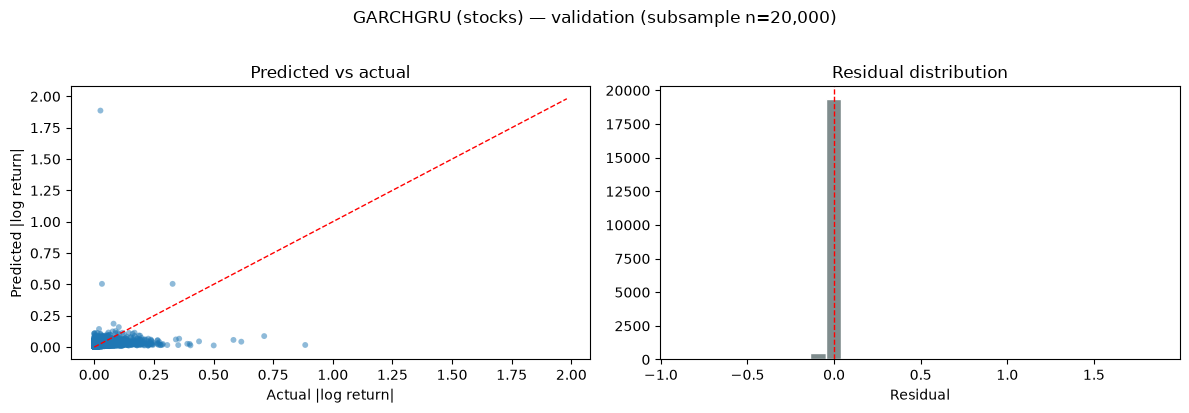

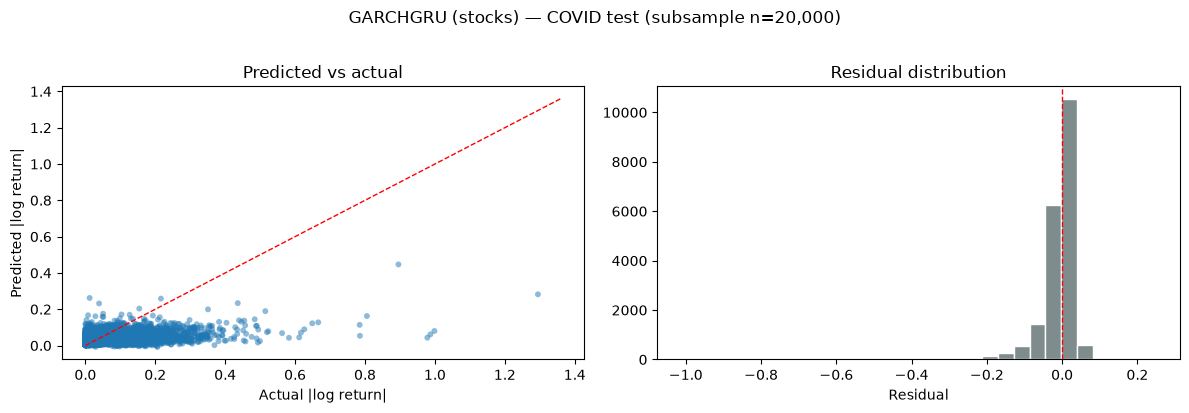

,Model,Val MAE,Crisis MAE,Val RMSE
0,GARCHGRU (stocks),0.013527,0.026107,0.027725
1,Persistence (val),0.017799,0.033201,NaN
2,Train-mean (test),0.017210,0.030583,NaN


In [17]:
if history is not None and not hist_df.empty:
    hist_df = pd.DataFrame(
        {
            "epoch": np.arange(1, len(history.history["loss"]) + 1),
            "train_loss": history.history["loss"],
            "val_loss": history.history["val_loss"],
            "val_mae": history.history["val_mae"],
        }
    )

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist_df["epoch"], hist_df["train_loss"], label="train")
    axes[0].plot(hist_df["epoch"], hist_df["val_loss"], label="val")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Huber loss")
    axes[0].set_title("Loss")
    axes[0].legend()
    axes[1].plot(hist_df["epoch"], hist_df["val_mae"], color="#2980b9")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("MAE")
    axes[1].set_title("Validation MAE")
    if best_epoch is not None:
        axes[1].axvline(best_epoch, color="#e74c3c", ls="--", lw=1, label=f"best={best_epoch}")
        axes[1].legend()
    fig.suptitle("GARCHGRU (stocks) — training", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print(
        "Skipping training-curve plots: interrupted run saved best-epoch weights only "
        f"(best_epoch={best_epoch}, best_val_mae={best_val_mae})."
    )

def plot_predictions(y_true: np.ndarray, y_pred: np.ndarray, title: str, max_points: int = 20_000) -> None:
    y_true = np.asarray(y_true, dtype=np.float32)
    y_pred = np.asarray(y_pred, dtype=np.float32)
    if len(y_true) > max_points:
        rng = np.random.default_rng(42)
        idx = rng.choice(len(y_true), max_points, replace=False)
        y_true = y_true[idx]
        y_pred = y_pred[idx]
        title = f"{title} (subsample n={max_points:,})"

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(y_true, y_pred, alpha=0.5, s=18, edgecolors="none")
    lim = max(float(np.max(y_true)), float(np.max(y_pred))) * 1.05
    axes[0].plot([0, lim], [0, lim], "r--", lw=1)
    axes[0].set_xlabel("Actual |log return|")
    axes[0].set_ylabel("Predicted |log return|")
    axes[0].set_title("Predicted vs actual")
    resid = y_pred - y_true
    axes[1].hist(resid, bins=30, color="#7f8c8d", edgecolor="white")
    axes[1].axvline(0, color="red", ls="--", lw=1)
    axes[1].set_xlabel("Residual")
    axes[1].set_title("Residual distribution")
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()

plot_predictions(y_val, val_pred, "GARCHGRU (stocks) — validation")
plot_predictions(y_test, test_pred, "GARCHGRU (stocks) — COVID test")

table = pd.DataFrame(
    [
        {
            "Model": "GARCHGRU (stocks)",
            "Val MAE": val_mae,
            "Crisis MAE": test_mae,
            "Val RMSE": val_rmse,
        },
        {
            "Model": "Persistence (val)",
            "Val MAE": persistence_mae_val,
            "Crisis MAE": persistence_mae_test,
            "Val RMSE": np.nan,
        },
        {
            "Model": "Train-mean (test)",
            "Val MAE": train_mean_mae_val,
            "Crisis MAE": train_mean_mae_test,
            "Val RMSE": np.nan,
        },
    ]
)
display(table)


## 5b) Extended performance diagnostics

Deeper views of calibration, tail behavior, and asymmetric errors. Works after a normal
training run **or** the 4b interrupted-run recovery cell.

In [ ]:
from sklearn.metrics import roc_auc_score

if "payload" not in globals():
    pred_path = MODELS_DIR / f"{ARTIFACT_STEM}_predictions.json"
    payload = json.loads(pred_path.read_text())
    val_pred = np.asarray(payload["predictions"]["val"]["y_pred"], dtype=np.float32)
    test_pred = np.asarray(payload["predictions"]["test"]["y_pred"], dtype=np.float32)
    y_val = np.asarray(payload["predictions"]["val"]["y_true"], dtype=np.float32)
    y_test = np.asarray(payload["predictions"]["test"]["y_true"], dtype=np.float32)
    val_mae = payload["val_mae"]
    test_mae = payload["crisis_mae"]
    asym_val = payload["asymmetric_errors"]["val"]
    asym_crisis = payload["asymmetric_errors"]["crisis"]
    baselines = payload.get("baselines", {})


def _split_metrics(name: str, y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    err = y_pred - y_true
    return {
        "split": name,
        "n": len(y_true),
        "mae": float(np.mean(np.abs(err))),
        "rmse": float(np.sqrt(np.mean(err**2))),
        "bias": float(np.mean(err)),
    }


def _decile_calibration(y_true: np.ndarray, y_pred: np.ndarray, n_bins: int = 10) -> pd.DataFrame:
    order = np.argsort(y_pred)
    bins = np.array_split(order, n_bins)
    rows = []
    for i, idx in enumerate(bins, start=1):
        yt = y_true[idx]
        yp = y_pred[idx]
        rows.append(
            {
                "decile": i,
                "mean_pred": float(np.mean(yp)),
                "mean_actual": float(np.mean(yt)),
                "mae": float(np.mean(np.abs(yp - yt))),
                "n": len(idx),
            }
        )
    return pd.DataFrame(rows)


def _tail_mae_curve(y_true: np.ndarray, y_pred: np.ndarray, quantiles: np.ndarray) -> pd.DataFrame:
    rows = []
    for q in quantiles:
        threshold = float(np.quantile(y_true, q))
        mask = y_true >= threshold
        if not mask.any():
            continue
        rows.append(
            {
                "quantile": q,
                "threshold": threshold,
                "mae": float(np.mean(np.abs(y_pred[mask] - y_true[mask]))),
                "n": int(mask.sum()),
            }
        )
    return pd.DataFrame(rows)


def _high_vol_auc(y_true: np.ndarray, y_pred: np.ndarray, quantile: float = 0.90) -> float:
    threshold = float(np.quantile(y_true, quantile))
    labels = (y_true >= threshold).astype(int)
    if labels.sum() == 0 or labels.sum() == len(labels):
        return float("nan")
    return float(roc_auc_score(labels, y_pred))


def _subsample(y_true: np.ndarray, y_pred: np.ndarray, n: int = 50_000, seed: int = 42):
    if len(y_true) <= n:
        return y_true, y_pred
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y_true), n, replace=False)
    return y_true[idx], y_pred[idx]


splits = {
    "validation": (y_val, val_pred),
    "crisis": (y_test, test_pred),
}

summary_rows = [_split_metrics(name, yt, yp) for name, (yt, yp) in splits.items()]
summary = pd.DataFrame(summary_rows)
display(summary)

# 1) Model vs baselines
baseline_rows = [
    {"Model": "GARCHGRU", "Val MAE": val_mae, "Crisis MAE": test_mae},
    {
        "Model": "Persistence",
        "Val MAE": baselines.get("persistence_mae_val", np.nan),
        "Crisis MAE": baselines.get("persistence_mae_test", np.nan),
    },
    {
        "Model": "Train-mean",
        "Val MAE": baselines.get("train_mean_mae_val", np.nan),
        "Crisis MAE": baselines.get("train_mean_mae_test", np.nan),
    },
]
baseline_df = pd.DataFrame(baseline_rows)
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(baseline_df))
width = 0.35
ax.bar(x - width / 2, baseline_df["Val MAE"], width, label="Val MAE", color="#2980b9")
ax.bar(x + width / 2, baseline_df["Crisis MAE"], width, label="Crisis MAE", color="#c0392b")
ax.set_xticks(x)
ax.set_xticklabels(baseline_df["Model"])
ax.set_ylabel("|error| MAE")
ax.set_title("GARCHGRU vs baselines")
ax.legend()
plt.tight_layout()
plt.show()

# 2) Asymmetric under/over errors
asym_df = pd.DataFrame(
    [
        {"split": "validation", "kind": "under", "mae": asym_val["under_mae"], "rate": asym_val["under_rate"]},
        {"split": "validation", "kind": "over", "mae": asym_val["over_mae"], "rate": 1 - asym_val["under_rate"]},
        {"split": "crisis", "kind": "under", "mae": asym_crisis["under_mae"], "rate": asym_crisis["under_rate"]},
        {"split": "crisis", "kind": "over", "mae": asym_crisis["over_mae"], "rate": 1 - asym_crisis["under_rate"]},
    ]
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, split in zip(axes, ("validation", "crisis")):
    part = asym_df[asym_df["split"] == split]
    ax.bar(part["kind"], part["mae"], color=["#e67e22", "#27ae60"])
    ax.set_title(f"{split.title()} asymmetric MAE")
    ax.set_ylabel("MAE")
    for i, row in part.reset_index(drop=True).iterrows():
        ax.text(i, row["mae"], f"{row['rate']:.1%}", ha="center", va="bottom", fontsize=9)
fig.suptitle("Under-prediction hurts more in the COVID window", y=1.02)
plt.tight_layout()
plt.show()

# 3) Calibration by predicted-vol decile
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, (yt, yp)) in zip(axes, splits.items()):
    cal = _decile_calibration(yt, yp)
    ax.plot(cal["mean_pred"], cal["mean_actual"], "o-", label="decile means")
    lim = max(cal["mean_pred"].max(), cal["mean_actual"].max()) * 1.05
    ax.plot([0, lim], [0, lim], "r--", lw=1, label="perfect")
    ax.set_xlabel("Mean predicted |return|")
    ax.set_ylabel("Mean actual |return|")
    ax.set_title(f"{name.title()} calibration")
    ax.legend()
fig.suptitle("Predicted-decile calibration", y=1.02)
plt.tight_layout()
plt.show()

# 4) MAE vs actual-vol quantile (tail stress)
quantiles = np.array([0.5, 0.7, 0.8, 0.9, 0.95, 0.99])
fig, ax = plt.subplots(figsize=(8, 4))
for name, (yt, yp) in splits.items():
    curve = _tail_mae_curve(yt, yp, quantiles)
    ax.plot(curve["quantile"], curve["mae"], "o-", label=name)
ax.set_xlabel("Actual-vol quantile threshold")
ax.set_ylabel("MAE above threshold")
ax.set_title("Tail MAE: errors rise on the highest-vol days")
ax.legend()
plt.tight_layout()
plt.show()

# 5) High-vol detection AUC (top 10% realized vol)
auc_rows = [
    {
        "split": name,
        "top10_vol_auc": _high_vol_auc(yt, yp, quantile=0.90),
        "top5_vol_auc": _high_vol_auc(yt, yp, quantile=0.95),
    }
    for name, (yt, yp) in splits.items()
]
display(pd.DataFrame(auc_rows))

# 6) Residual distributions (subsampled)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, (yt, yp)) in zip(axes, splits.items()):
    yt_s, yp_s = _subsample(yt, yp)
    resid = yp_s - yt_s
    ax.hist(resid, bins=60, color="#7f8c8d", alpha=0.85, edgecolor="white")
    ax.axvline(0, color="red", ls="--", lw=1)
    ax.set_title(f"{name.title()} residuals")
    ax.set_xlabel("predicted - actual")
fig.suptitle("Residual distributions (subsampled)", y=1.02)
plt.tight_layout()
plt.show()

# 7) Error vs actual level (binned)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, (yt, yp)) in zip(axes, splits.items()):
    bins = np.quantile(yt, np.linspace(0, 1, 11))
    bins[0] -= 1e-8
    bin_idx = np.digitize(yt, bins[1:-1])
    bin_centers, bin_mae = [], []
    for b in range(1, 11):
        mask = bin_idx == b
        if not mask.any():
            continue
        bin_centers.append(float(np.mean(yt[mask])))
        bin_mae.append(float(np.mean(np.abs(yp[mask] - yt[mask]))))
    ax.plot(bin_centers, bin_mae, "o-", color="#8e44ad")
    ax.set_xlabel("Actual |return| (bin mean)")
    ax.set_ylabel("MAE")
    ax.set_title(f"{name.title()} error vs level")
fig.suptitle("Does error grow with realized volatility?", y=1.02)
plt.tight_layout()
plt.show()

print(
    f"Full-universe diagnostics | symbols={payload.get('n_symbols')} "
    f"| best_epoch={payload.get('best_epoch')}"
)

## 6) Save model and prediction artifacts

Save TensorFlow model files and JSON metrics/predictions for cross-platform comparison.

In [18]:
artifact_stem = ARTIFACT_STEM
best_model_path = MODELS_DIR / f"{artifact_stem}_best.keras"
final_model_path = MODELS_DIR / f"{artifact_stem}_final.keras"
pred_path = MODELS_DIR / f"{artifact_stem}_predictions.json"

model.save(best_model_path)
model.save(final_model_path)

history_records = (
    hist_df.to_dict(orient="records")
    if "hist_df" in globals() and not hist_df.empty
    else payload.get("history", [])
)

payload = {
    "job_id": JOB_ID,
    "job_slug": JOB_SLUG,
    "architecture": MODEL_ARCHITECTURE,
    "universe": UNIVERSE,
    "model": f"{artifact_stem}_tensorflow",
    "run_mode": RUN_MODE,
    "dataset_tag": DATASET_TAG,
    "n_symbols": bundle.cfg.get("n_symbols"),
    "framework": "tensorflow" if ARCHITECTURE != "xgb" else getattr(model, "backend", "tree"),
    "target_type": bundle.cfg["target_type"],
    "n_features": len(bundle.feature_cols),
    "lookback_days": bundle.cfg["lookback_days"],
    "feature_cols": bundle.feature_cols,
    "best_epoch": best_epoch,
    "best_val_mae": best_val_mae,
    "val_mae": val_mae,
    "val_rmse": val_rmse,
    "crisis_mae": test_mae,
    "test_rmse": test_rmse,
    "asymmetric_errors": {
        "val": asym_val,
        "crisis": asym_crisis,
    },
    "baselines": {
        "persistence_mae_val": persistence_mae_val,
        "persistence_mae_test": persistence_mae_test,
        "train_mean_mae_val": train_mean_mae_val,
        "train_mean_mae_test": train_mean_mae_test,
    },
    "baseline_comparison": baseline_comparison,
    "huber_comparison": huber_comparison if LOSS == "qlike" else {"huber_trained": False},
    "train_config": {
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "patience": PATIENCE,
        "lr": LR,
        "loss": LOSS,
        "architecture": ARCHITECTURE,
        "device": device_info,
        "sequences_name": sequences_name,
        "storage_format": bundle.storage_format,
    },
    "history": history_records,
    "predictions": {
        "val": {"y_true": y_val.tolist(), "y_pred": val_pred.tolist()},
        "test": {"y_true": y_test.tolist(), "y_pred": test_pred.tolist()},
    },
    "trained_at": datetime.now(timezone.utc).isoformat(),
}

with open(pred_path, "w") as f:
    json.dump(payload, f, indent=2)

print("Saved artifacts:")
print(f"- {best_model_path}")
print(f"- {final_model_path}")
print(f"- {pred_path}")


Saved artifacts:
- /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/models/garchgru_vol_risk_stocks_tf_best.keras
- /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/models/garchgru_vol_risk_stocks_tf_final.keras
- /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/models/garchgru_vol_risk_stocks_tf_predictions.json
